<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "datos" / "crudos" / "milan_airbnb.csv").is_file():
    if (PROJECT_DIR.parent / "datos" / "crudos" / "milan_airbnb.csv").is_file():
        PROJECT_DIR = PROJECT_DIR.parent
    elif (PROJECT_DIR / "tp-mpg" / "datos" / "crudos" / "milan_airbnb.csv").is_file():
        PROJECT_DIR = PROJECT_DIR / "tp-mpg"
    elif str(PROJECT_DIR) == "/content":
        !git clone https://github.com/santidrelew/tp-mpg.git
        PROJECT_DIR = PROJECT_DIR / "tp-mpg"

RAW_DATA_PATH = PROJECT_DIR / "datos" / "crudos" / "milan_airbnb.csv"
if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError(f"No se encontró el CSV crudo: {RAW_DATA_PATH}")

# Activar solo si se quieren generar los archivos derivados de este EDA.
EXPORTAR_CSV = False
DIRECTORIO_EXPORTACION = PROJECT_DIR / "datos" / "exportaciones_eda"

In [41]:
# Importamos todas las librerías necesarias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
from math import ceil
from scipy import stats

# **1 - Exploración de los datos del dataset AirBnB Milan**

## **1.1 - CARGA DEL DATASET**

In [42]:
print(f"Archivo de entrada: {RAW_DATA_PATH.relative_to(PROJECT_DIR)}")

Archivo de entrada: datos\crudos\milan_airbnb.csv


In [43]:
df_raw = pd.read_csv(RAW_DATA_PATH, index_col=0)
pd.set_option('display.max_columns', len(df_raw.columns)) # Para ver todas las columnas
pd.set_option('display.max_rows', 100)
df_raw

,id,host_id,host_location,host_response_time,host_response_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,zipcode,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,daily_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,TV,WiFi,Air_Condition,Wheelchair_accessible,Kitchen,Breakfast,Elevator,Heating,Washer,Iron,Host_greets_you,Paid_parking_on_premises,Luggage_dropoff_allowed,Long_term_stays_allowed,Doorman,Pets_allowed,Smoking_allowed,Suitable_for_events,24_hour_check_in
1,73892,387110,1,1,57,0,3,1,1,1,20121,45.47015,9.19134,Entire home/apt,2,3,1,1,1,94,1,45,1,0,2,29,59,89,364,84,94,9,9,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
2,74169,268127,1,1,57,0,1,1,0,1,20121,45.47169,9.18412,Entire home/apt,4,3,1,1,1,125,31,30,1,0,2,0,0,9,284,3,100,10,10,10,10,10,9,0,0,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0
3,77958,387110,1,1,57,0,3,1,1,1,20121,45.47117,9.19135,Entire home/apt,2,3,1,1,1,100,1,45,1,0,2,29,59,89,364,70,97,9,10,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
4,93025,499743,1,1,57,0,1,1,0,1,20121,45.47204,9.19640,Entire home/apt,3,3,1,2,1,120,48,57,2,40,2,10,40,70,160,57,97,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0
5,132705,391011,1,1,57,1,2,1,0,1,20135,45.45934,9.20609,Entire home/apt,2,3,0,1,3,70,13,45,1,0,30,27,57,87,362,44,90,9,9,10,10,9,9,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9318,35954783,56584596,1,1,57,0,1,1,1,9,20124,45.48586,9.19706,Entire home/apt,2,3,1,1,1,80,1,1,1,0,1,1,1,1,1,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0
9319,36023503,271013325,1,1,57,0,1,1,0,9,20124,45.48170,9.18968,Entire home/apt,6,5,2,2,1,900,1,69,2,30,1,9,9,18,204,2,100,10,10,10,10,10,10,1,0,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0
9320,36071908,271354203,1,0,57,0,1,1,0,9,20159,45.49807,9.18476,Entire home/apt,2,3,1,1,1,70,1,20,1,20,1,30,60,90,365,3,100,9,10,10,10,9,10,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0
9321,36305676,171239896,1,1,40,0,3,1,0,9,20158,45.50107,9.18210,Entire home/apt,4,3,1,2,1,65,1,1,1,0,1,29,59,89,364,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0


In [44]:
# Ponemos nuestra columna target daily_price al final
col_target = df_raw.pop("daily_price")
df_raw.insert(len(df_raw.columns), col_target.name, col_target)

El dataset contiene información sobre alojamientos publicados en Airbnb en la ciudad de Milán (Italia), considerando únicamente propiedades que se alquilan completas.

El objetivo de nuestro problema de regresión es **predecir el precio por noche (`daily_price`)** a partir de las características de los alojamientos, sus anfitriones, ubicación, disponibilidad y evaluaciones.

Copiamos el dataset para hacer el análisis del dataset

In [45]:
df_analisis = df_raw.copy()

## **1.2 y 1.3 - ANALISIS DESCRIPTIVO Y LIMPIEZA DE DATOS**

Para empezar, eliminaremos del dataset la variable "room_type", ya que solo tiene un unico valor para todas las celdas.

In [46]:
valores_unicos = df_analisis['room_type'].unique()
print(valores_unicos)


df_analisis = df_analisis.drop(columns=['room_type'])

<StringArray>
['Entire home/apt']
Length: 1, dtype: str


### DETECCION DE DATOS FALTANTES Y DUPLICADOS

In [47]:
# Verificamos si hay valores nulos en el DataFrame
sum(df_analisis.isnull().sum())

0

No nulos en ninguna columna

Chequeamos si hay duplicados: nos fijamos por el `id`

In [48]:
# Verificamos que ningun ID se repita
es_id_unico = df_analisis["id"].is_unique
cant_ids_duplicados = df_analisis["id"].duplicated().sum()

print(f"¿La columna 'id' es clave unica?: {es_id_unico}")
print(f"Cantidad de IDs repetidos: {cant_ids_duplicados}")

# Buscamos que no hayan dos celdas exactamente iguales con distinto ID
cols_sin_id = [col for col in df_analisis.columns if col not in ["id", "host_id"]]
duplicados_atributos_completos = df_analisis.duplicated(
    subset=cols_sin_id, keep=False
).sum()

# Verificamos que la misma propiedad no este publicada bajo distinto ID
# Definimos atributos físicos y de ubicación exacta:
clave_negocio = [
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "daily_price",
]
duplicados_negocio = df_analisis.duplicated(subset=clave_negocio, keep=False).sum()

print(
    f"Registros con todos los atributos identicos (salvo ID):"
    f" {duplicados_atributos_completos}"
)
print(
    f"Registros que comparten ubicacion exacta y caracteristicas clave:"
    f" {duplicados_negocio}"
)

¿La columna 'id' es clave unica?: True
Cantidad de IDs repetidos: 0
Registros con todos los atributos identicos (salvo ID): 0
Registros que comparten ubicacion exacta y caracteristicas clave: 0


Por lo tanto, confirmamos que no hay ningun tipo de dato duplicado.

Antes de continuar, eliminaremos defintivamente de nuestro modelo las variables:
* id
* host_id
* zipcode

In [49]:
df_analisis = df_analisis.drop(columns=['id', 'host_id', 'zipcode'], errors='ignore')

### DETECCION DE VARIABLES CATEGORICAS

In [50]:
cols_categoricas = [
    col
    for col in df_analisis.columns
    if set(df_analisis[col].dropna().unique()).issubset({0, 1})
]
cols_continuas = [col for col in df_analisis.columns if col not in cols_categoricas]

print(f"Total de columnas en el dataset: {df_analisis.shape[1]}")
print(f"Variables categoricas identificadas ({len(cols_categoricas)}): {cols_categoricas}\n")
print(
    f"Variables continuas identificadas ({len(cols_continuas)}):"
    f" {cols_continuas}\n"
)

Total de columnas en el dataset: 56
Variables categoricas identificadas (28): ['host_location', 'host_response_time', 'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable', 'cancellation_policy', 'require_guest_profile_picture', 'require_guest_phone_verification', 'TV', 'WiFi', 'Air_Condition', 'Wheelchair_accessible', 'Kitchen', 'Breakfast', 'Elevator', 'Heating', 'Washer', 'Iron', 'Host_greets_you', 'Paid_parking_on_premises', 'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman', 'Pets_allowed', 'Smoking_allowed', 'Suitable_for_events', '24_hour_check_in']

Variables continuas identificadas (28): ['host_response_rate', 'host_total_listings_count', 'neighbourhood_cleansed', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'bed_type', 'security_deposit', 'cleaning_fee', 'guests_included', 'extra_people', 'minimum_nights', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_review

Sin embargo, 'neighbourhood_cleansed' y 'bed_type' son variables categoricas, asi que modificamos la lista manualmente

In [51]:
cols_a_mover = ["neighbourhood_cleansed", "bed_type"]

cols_continuas = [col for col in cols_continuas if col not in cols_a_mover]

### ANALISIS DE VARIABLES CATEGORICAS

Variables categoricas binarias:

In [52]:
tabla_analisis_categoricas = (
    pd.DataFrame({
        "Proporcion 0 (%)": (df_analisis[cols_categoricas] == 0).mean() * 100,
        "Proporcion 1 (%)": (df_analisis[cols_categoricas] == 1).mean() * 100,
    })
    .round(2)
    .sort_values(by="Proporcion 1 (%)", ascending=False)
)

display(tabla_analisis_categoricas)

,Proporcion 0 (%),Proporcion 1 (%)
host_has_profile_pic,0.04,99.96
Heating,1.93,98.07
Kitchen,3.27,96.73
host_location,4.04,95.96
WiFi,7.14,92.86
TV,12.75,87.25
host_response_time,13.08,86.92
cancellation_policy,14.25,85.75
Iron,18.79,81.21
Washer,18.97,81.03


Variable politomica:

In [53]:
distribucion_camas = pd.DataFrame({
    'Cantidad': df_analisis['bed_type'].value_counts(),
    'Porcentaje (%)': df_analisis['bed_type'].value_counts(normalize=True) * 100
}).round(2)

display(distribucion_camas)

,Cantidad,Porcentaje (%)
bed_type,,
1,9091,97.52
2,205,2.20
3,17,0.18
4,5,0.05
5,4,0.04


Desde este analisis, eliminaremos las siguientes variables de nuestro modelo dada su poca varianza (< 5% en la clase minoritaria)
* host_has_profile_pic
* heating
* bed_type
* kitchen
* host_location
* require_guest_profile_picture
* require_guest_phone_verification
* suitable_for_events
* wheelchair_accesible


Ademas, hemos decidido eliminar tambien las siguientes variables:

* host_response_time, host_identity_verified

No fija el precio del alquiler; es una métrica de soporte de la plataforma. Por esta misma razon, tambien eliminaremos la variable continua:
* host_response_rate

In [54]:
df_analisis = df_analisis.drop(columns=[
    "host_has_profile_pic", "Heating", "bed_type", "Kitchen", "host_location",
    "require_guest_profile_picture", "require_guest_phone_verification", "host_identity_verified",
    "Suitable_for_events", "Wheelchair_accessible", "host_response_time", "host_response_rate"
])

### ANALISIS DE VARIABLES CONTINUAS / CUANTITATIVAS

Solo vamos a analizar variables cuantitativas continuas/discretas. Vamos a excluir del analisis coordenadas fijas de la propiedad, columnas relacionadas a reviews (ya que se encuentran siempre dentro de un rango fijo) y columnas de disponibilidad diaria (tambien tienen un rango acotado).


In [55]:
cols_excluir = ["latitude", "longitude", "log_daily_price", "host_response_rate", "review_scores_location",
                "review_scores_checkin", "review_scores_communication", "review_scores_accuracy",
                "review_scores_cleanliness", "review_scores_value", "review_scores_rating",
                "availability_30", "availability_60", "availability_90", "availability_365"]
cols_outliers = [
    col
    for col in cols_continuas
    if col not in cols_excluir and pd.api.types.is_numeric_dtype(df_analisis[col])
]

In [56]:
reporte_outliers = []

for col in cols_outliers:
  serie = df_analisis[col].dropna()

  # Z-score
  z = np.abs(stats.zscore(serie))
  n_z = (z > 3).sum()

  # Tukey IQR
  q1 = serie.quantile(0.25)
  q3 = serie.quantile(0.75)
  iqr = q3 - q1
  lim_inf = q1 - 1.5 * iqr
  lim_sup = q3 + 1.5 * iqr
  n_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()

  reporte_outliers.append({
      "Variable": col,
      "Min": round(serie.min(), 2),
      "Q1": round(q1, 2),
      "Mediana": round(serie.median(), 2),
      "Q3": round(q3, 2),
      "Max": round(serie.max(), 2),
      "Outliers (|Z|>3)": n_z,
      "% Outliers (Z)": round((n_z / len(serie)) * 100, 2),
      "Outliers (IQR)": n_iqr,
      "% Outliers (IQR)": round((n_iqr / len(serie)) * 100, 2),
  })

  df_tabla_outliers = pd.DataFrame(reporte_outliers).sort_values(
    by="% Outliers (IQR)", ascending=False
)

display(df_tabla_outliers.reset_index(drop=True))

,Variable,Min,Q1,Mediana,Q3,Max,Outliers (|Z|>3),% Outliers (Z),Outliers (IQR),% Outliers (IQR)
0,host_total_listings_count,0,1.0,2.0,7.0,847,183,1.96,1605,17.22
1,bathrooms,1,3.0,3.0,3.0,17,148,1.59,1459,15.65
2,number_of_reviews,1,4.0,14.0,44.0,791,234,2.51,982,10.53
3,daily_price,10,59.0,75.0,107.0,3000,86,0.92,885,9.49
4,minimum_nights,1,1.0,2.0,2.0,365,35,0.38,874,9.38
5,guests_included,1,1.0,2.0,2.0,18,124,1.33,565,6.06
6,cleaning_fee,1,30.0,45.0,57.0,108,0,0.00,216,2.32
7,accommodates,1,2.0,4.0,4.0,16,89,0.95,198,2.12
8,security_deposit,1,1.0,1.0,48.0,143,182,1.95,188,2.02
9,bedrooms,0,1.0,1.0,2.0,10,106,1.14,106,1.14


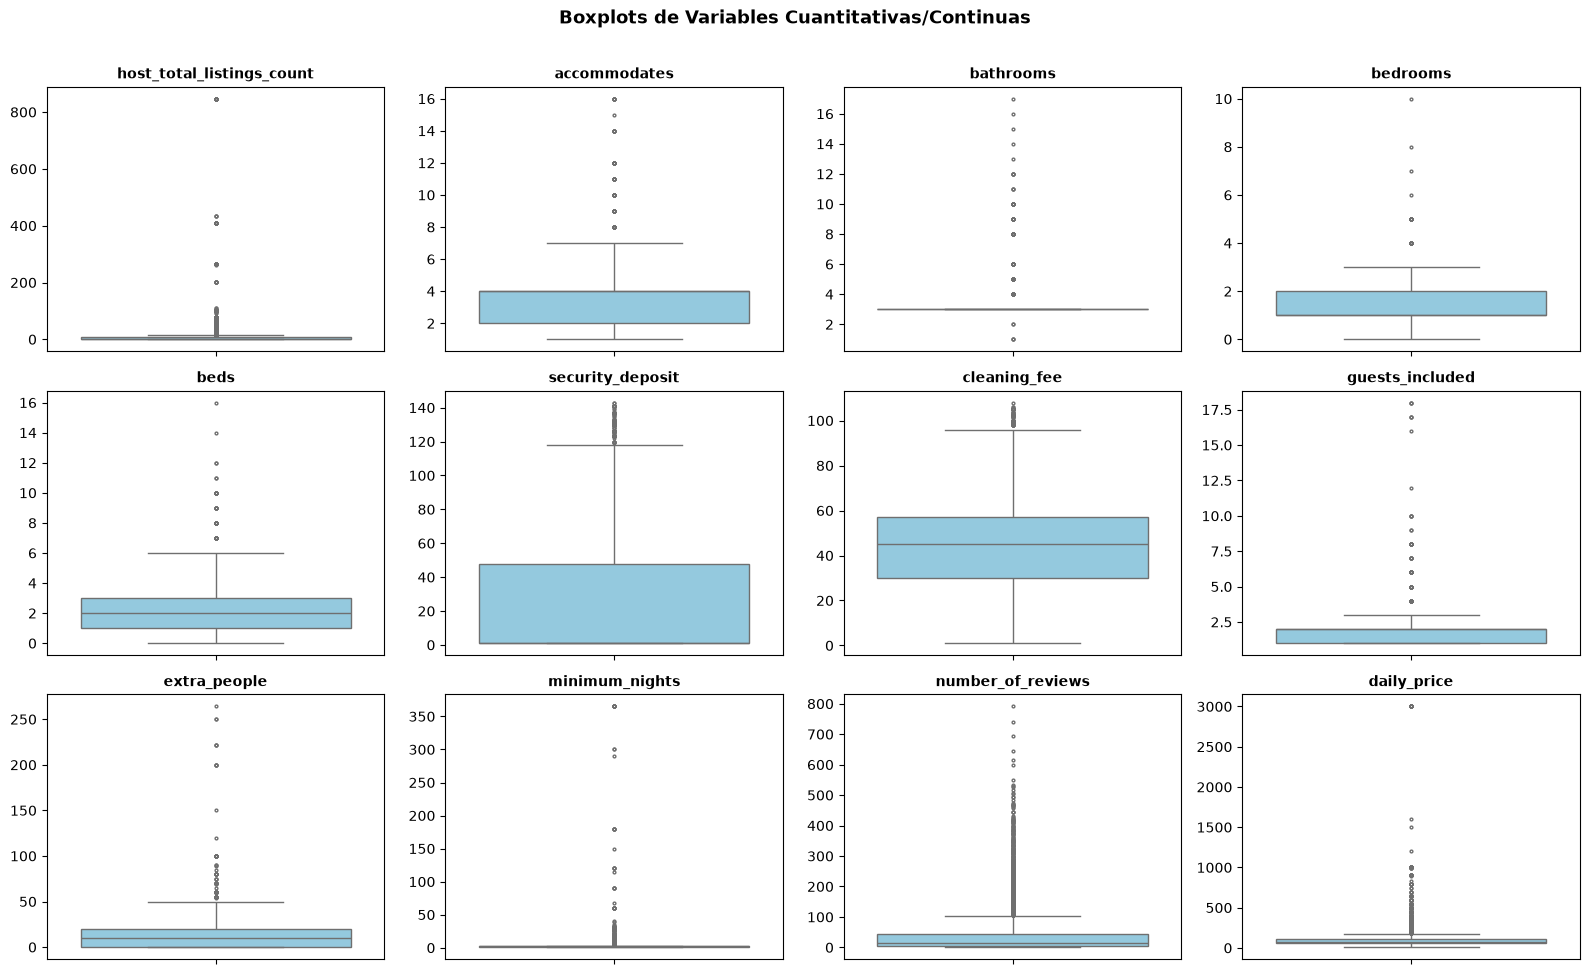

In [57]:
n_vars = len(cols_outliers)
n_cols = 4
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.2))
axes = axes.flatten()

for i, col in enumerate(cols_outliers):
  sns.boxplot(y=df_analisis[col], ax=axes[i], color="skyblue", fliersize=2)
  axes[i].set_title(col, fontsize=10, fontweight="bold")
  axes[i].set_ylabel("")

plt.suptitle(
    "Boxplots de Variables Cuantitativas/Continuas",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

Todas las 12 variables analizadas presentan outliers analiticos o graficos, salvo excepciones puntuales:
* En los boxplots: Las 12 variables muestran puntos individuales por fuera de los bigotes superiores.
* En el metodo Tukey: Todas superan el corte.
* En el metodo $Z$-Score: 11 de las 12 variables tienen registros que se alejan a mas de 3 desvios estandar de la media. La unica que no presenta outliers bajo este criterio es cleaning_fee (0%).  

In [58]:
# Ver distribución de baños para detectar cargas erróneas
print(df_analisis["bathrooms"].value_counts().sort_index())

bathrooms
1        3
2        2
3     7863
4      155
5     1122
6       29
8      108
9       10
10      17
11       3
12       5
13       1
14       1
15       1
16       1
17       1
Name: count, dtype: int64


In [59]:
# Ver anomalías extremas en baños
display(df_analisis[df_analisis["bathrooms"] > 10][["accommodates", "bedrooms", "beds", "bathrooms", "daily_price"]])

,accommodates,bedrooms,beds,bathrooms,daily_price
14,5,1,4,17,290
473,8,3,4,14,652
724,11,5,8,11,650
1343,10,4,6,11,800
1904,14,5,7,12,490
2029,14,5,8,12,304
2099,8,4,4,12,400
3278,8,4,8,11,199
6241,12,5,8,12,630
6687,8,4,4,13,3000


Desde este analisis, concluimos en eliminar las filas: 14 y 7882 ya que son datos absurdos.

In [60]:
df_analisis = df_analisis.drop([14, 7882])

Ahora, vamos a comprobar que ninguna propiedad este poniendo su precio de acuerdo a una cantidad de huespedes que en realidad superan los que la propiedad puede acomodar.

In [61]:
# Filtrar filas donde los huéspedes incluidos superan la capacidad máxima
inconsistencias_huespedes = df_analisis[df_analisis['guests_included'] > df_analisis['accommodates']]

print(f"Cantidad de registros con inconsistencia lógica (guests_included > accommodates): {len(inconsistencias_huespedes)}")

# Visualizar las columnas clave de estos casos anómalos
if len(inconsistencias_huespedes) > 0:
    display(inconsistencias_huespedes[['accommodates', 'guests_included', 'extra_people', 'daily_price']])

Cantidad de registros con inconsistencia lógica (guests_included > accommodates): 23


,accommodates,guests_included,extra_people,daily_price
13,4,5,20,290
81,2,3,50,90
860,6,16,10,149
3102,2,4,20,80
3225,2,17,0,52
3371,2,17,0,52
3421,2,18,0,52
3551,2,18,0,63
4291,3,4,15,60
4405,2,4,10,150


Eliminamos estas filas, ya que representan una contradiccion: una propiedad no puede cobrar un precio base por una cantidad de huespedes que fisicamente no entran en la propiedad.

In [62]:
df_analisis = df_analisis[df_analisis['guests_included'] <= df_analisis['accommodates']]

### MATRIZ DE CORRELACION

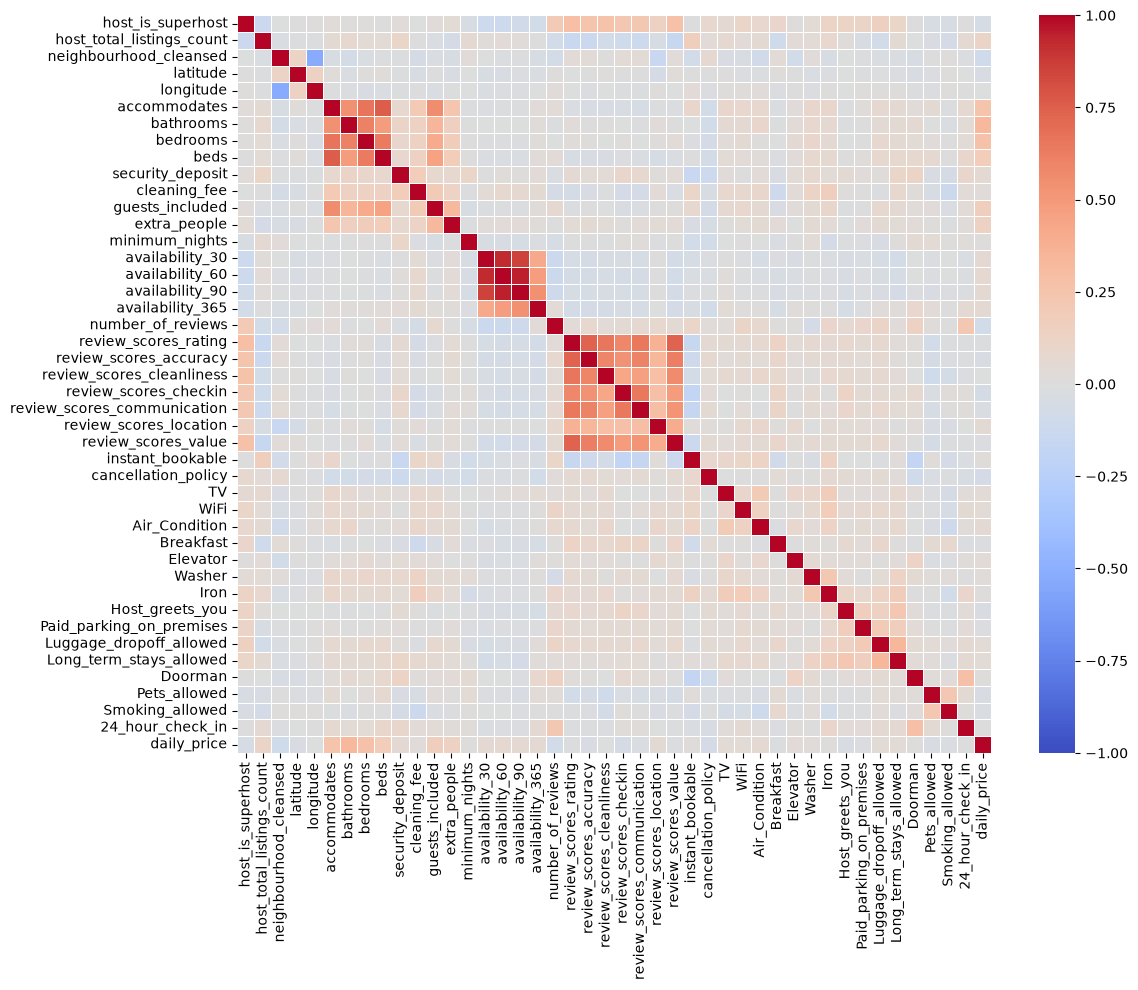

In [63]:
cols_para_corr = [
    col for col in df_analisis.columns if col not in ['id', 'host_id']
]

matriz_corr = df_analisis[cols_para_corr].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    matriz_corr,
    annot=False,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.tight_layout()
plt.show()

* Podemos ver una relación positiva directa entre daily_price y las variables de dimensiones fisicas (bathrooms, bedrooms, accommodates). Esto es intuitivo ya que la capacidad y el tamaño del inmueble fijan la principal estructura de precios.

* Se detecta una alta correlacion cruzada dentro del bloque de capacidad (accommodates vs. beds) y en las metricas de disponibilidad temporal (availability_*).

* A su vez, podemos ver que las variables sobre reviews tienen una alta correlacion entre ellas.

A partir de este analisis, eliminaremos de nuestro modelo las siguientes variables:

* availability_30, availability_60, availability_90: En la matriz forman un bloque rojo entre ellas. La disponibilidad a 30, 60 y 90 días miden prácticamente lo mismo en distintas ventanas temporales cortas. Nos quedamos unicamente con availability_365, ya que captura la disponibilidad anual global del alojamiento sin duplicar informacion redundante.
* review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value: Todas estas metricas presentan bloques de correlacion muy elevados entre si (tonos anaranjados/rojos fuertes). Los huespedes tienden a calificar de manera globalmente similar todos los rubros, por lo que incluirlos a todos nos deja informacion repetida.
* beds: las variables accomodates, bedrooms, bathrooms y beds tienen correlacion entre si, pero consideramos que beds y accomodates tienen la mayor correlacion, por lo que eliminaremos la primera para nuestro modelo.

In [64]:
df_analisis.drop(columns=[
    "availability_30", "availability_60", "availability_90",
    "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin",
    "review_scores_communication", "review_scores_location", "review_scores_value",
    "beds"
], inplace=True)

## SELECCION DE VARIABLES

### 1) Identificación e información del anfitrión

- ❌**`id`**: Identificador único del apartamento.
- ❌**`host_id`**: Identificador único del anfitrión.
- ❌**`host_location`**: Indica si el anfitrión reside en Italia. `1 = Italia`, `0 = fuera de Italia`.
- ❌**`host_response_time`**: Indica la rapidez de respuesta del anfitrión. `1 = rápida`, `0 = lenta`.
- ❌**`host_response_rate`**: Porcentaje de consultas respondidas por el anfitrión.
- ✅**`host_is_superhost`**: Indica si el anfitrión tiene la categoría Superhost. `1 = sí`, `0 = no`.
- ✅**`host_total_listings_count`**: Cantidad total de propiedades publicadas por el anfitrión.
- ❌**`host_has_profile_pic`**: Indica si el anfitrión tiene una foto de perfil. `1 = sí`, `0 = no`.
- ❌**`host_identity_verified`**: Indica si Airbnb verificó la identidad del anfitrión. `1 = sí`, `0 = no`.

### 2) Ubicación del alojamiento


- ✅**`neighbourhood_cleansed`**: Barrio o zona de la ciudad donde se encuentra el alojamiento, según la clasificación normalizada de Airbnb.
- ❌zipcode`**: Código postal del alojamiento.
- ✅**`latitude`**: Latitud geográfica del alojamiento.
- ✅**`longitude`**: Longitud geográfica del alojamiento.

### 3) Características del alojamiento


- ❌**`room_type`**: Tipo de alojamiento ofrecido. En este dataset se consideran únicamente apartamentos o viviendas completas.
- ✅**`accommodates`**: Cantidad máxima de huéspedes que puede alojar la propiedad.
- ✅**`bathrooms`**: Cantidad de baños del alojamiento.
- ✅**`bedrooms`**: Cantidad de dormitorios del alojamiento.
- ❌**`beds`**: Cantidad de camas disponibles.
- ❌**`bed_type`**: Tipo de cama ofrecida, representado mediante categorías.


### 4) Precios y condiciones de reserva

- ❌**`security_deposit`**: Depósito de garantía solicitado por el anfitrión.
- ❌**`cleaning_fee`**: Cargo adicional por limpieza del alojamiento.
- ✅**`guests_included`**: Cantidad de huéspedes incluidos en el precio base.
- ❌**`extra_people`**: Cargo adicional por cada huésped extra.
- ✅**`minimum_nights`**: Cantidad mínima de noches exigida para reservar el alojamiento.

In [65]:
df_analisis.drop(columns=["security_deposit", "cleaning_fee", "extra_people"], inplace=True)

Justificación: estas variables forman parte de la estructura de precios definida por el anfitrión y pueden estar estrechamente relacionadas con el propio daily_price.

Se decide excluirlas para que el modelo estime el precio por noche principalmente a partir de características del alojamiento, y no de otros importes fijados simultáneamente por el anfitrión.

Esto no implica necesariamente que constituyan data leakage, sino que responde al enfoque elegido para el problema de predicción.

Se conservan minimum_nights y guests_included, ya que describen condiciones de reserva que pueden influir en el precio base.

### 5) Disponibilidad

- ❌**`availability_30`**: Cantidad de días disponibles para reservar durante los próximos 30 días.
- ❌**`availability_60`**: Cantidad de días disponibles para reservar durante los próximos 60 días.
- ❌**`availability_90`**: Cantidad de días disponibles para reservar durante los próximos 90 días.
- ✅**`availability_365`**: Cantidad de días disponibles para reservar durante los próximos 365 días.

### 6) Reseñas y evaluaciones

- ✅**`number_of_reviews`**: Cantidad total de reseñas recibidas por el alojamiento.
- ✅**`review_scores_rating`**: Puntuación general del alojamiento otorgada por los huéspedes (escala de 0 a 100).
- ❌**`review_scores_accuracy`**: Puntuación sobre qué tan precisa es la descripción del alojamiento (0 a 10).
- ❌**`review_scores_cleanliness`**: Puntuación de limpieza del alojamiento (0 a 10).
- ❌**`review_scores_checkin`**: Puntuación del proceso de ingreso o check-in (0 a 10).
- ❌**`review_scores_communication`**: Puntuación de la comunicación con el anfitrión (0 a 10).
- ❌**`review_scores_location`**: Puntuación de la ubicación del alojamiento (0 a 10).
- ❌**`review_scores_value`**: Puntuación de la relación calidad-precio del alojamiento (0 a 10).


### 7) Políticas y condiciones adicionales

- ❌**`instant_bookable`**: Indica si el alojamiento permite realizar reservas instantáneas sin aprobación previa del anfitrión.
- ❌**`cancellation_policy`**: Tipo de política de cancelación establecida por el anfitrión.
- ❌**`require_guest_profile_picture`**: Indica si se exige que el huésped tenga una foto de perfil.
- ❌**`require_guest_phone_verification`**: Indica si se exige que el huésped tenga su número telefónico verificado.


In [66]:
df_analisis.drop(columns=["instant_bookable","cancellation_policy",], inplace=True)

Se eliminan todas estas, ya que no depende del alojamiento en si, sino del anfitrion

### 8) Servicios y comodidades

- ✅**`TV`**: Disponibilidad de televisión.
- ✅**`WiFi`**: Disponibilidad de conexión inalámbrica a Internet.
- ✅**`Air_Condition`**: Disponibilidad de aire acondicionado.
- ❌**`Wheelchair_accessible`**: Accesibilidad para personas que utilizan silla de ruedas.
- ✅**`Kitchen`**: Disponibilidad de cocina.
- ✅**`Breakfast`**: Desayuno incluido u ofrecido.
- ✅**`Elevator`**: Disponibilidad de ascensor.
- ✅**`Heating`**: Disponibilidad de calefacción.
- ✅**`Washer`**: Disponibilidad de lavarropas.
- ✅**`Iron`**: Disponibilidad de plancha.
- ✅**`Host_greets_you`**: Indica si el anfitrión recibe personalmente a los huéspedes.
- ✅**`Paid_parking_on_premises`**: Disponibilidad de estacionamiento pago dentro de la propiedad.
- ✅**`Luggage_dropoff_allowed`**: Posibilidad de dejar el equipaje antes del check-in o después del check-out.
- ✅**`Long_term_stays_allowed`**: Indica si se permiten estadías prolongadas.
- ✅**`Doorman`**: Disponibilidad de portero o servicio de recepción.
- ✅**`Pets_allowed`**: Indica si se permiten mascotas.
- ✅**`Smoking_allowed`**: Indica si se permite fumar.
- *❌*`Suitable_for_events`**: Indica si el alojamiento permite organizar eventos.
- ✅**`24_hour_check_in`**: Disponibilidad de ingreso al alojamiento durante las 24 horas.

## Análisis exploratorio de la variable objetivo

In [67]:
df_analisis.columns

Index(['host_is_superhost', 'host_total_listings_count',
       'neighbourhood_cleansed', 'latitude', 'longitude', 'accommodates',
       'bathrooms', 'bedrooms', 'guests_included', 'minimum_nights',
       'availability_365', 'number_of_reviews', 'review_scores_rating', 'TV',
       'WiFi', 'Air_Condition', 'Breakfast', 'Elevator', 'Washer', 'Iron',
       'Host_greets_you', 'Paid_parking_on_premises',
       'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
       'Pets_allowed', 'Smoking_allowed', '24_hour_check_in', 'daily_price'],
      dtype='str')

In [68]:
df_analisis["daily_price"].describe()

count    9297.000000
mean      103.707863
std       138.088896
min        10.000000
25%        59.000000
50%        75.000000
75%       106.000000
max      3000.000000
Name: daily_price, dtype: float64

In [69]:

bins = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 2000, 3000]

# 2. Definir las etiquetas (labels) descriptivas para cada rango
labels = [
    '0-100', '100-200', '200-300', '300-400', '400-500',
    '500-600', '600-700', '700-800', '800-900', '900-1000',
    '1000-2000', '2000-3000'
]

df_aux = df_analisis.copy()
df_aux["rango_precio"] = pd.cut(
    df_aux['daily_price'],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

# Vemos cuantas filas estan en cada rango de valores
conteo_rangos = df_aux['rango_precio'].value_counts().sort_index()

print(conteo_rangos)

rango_precio
0-100        6900
100-200      1824
200-300       350
300-400        80
400-500        57
500-600        21
600-700        12
700-800        10
800-900        10
900-1000       18
1000-2000       3
2000-3000      12
Name: count, dtype: int64


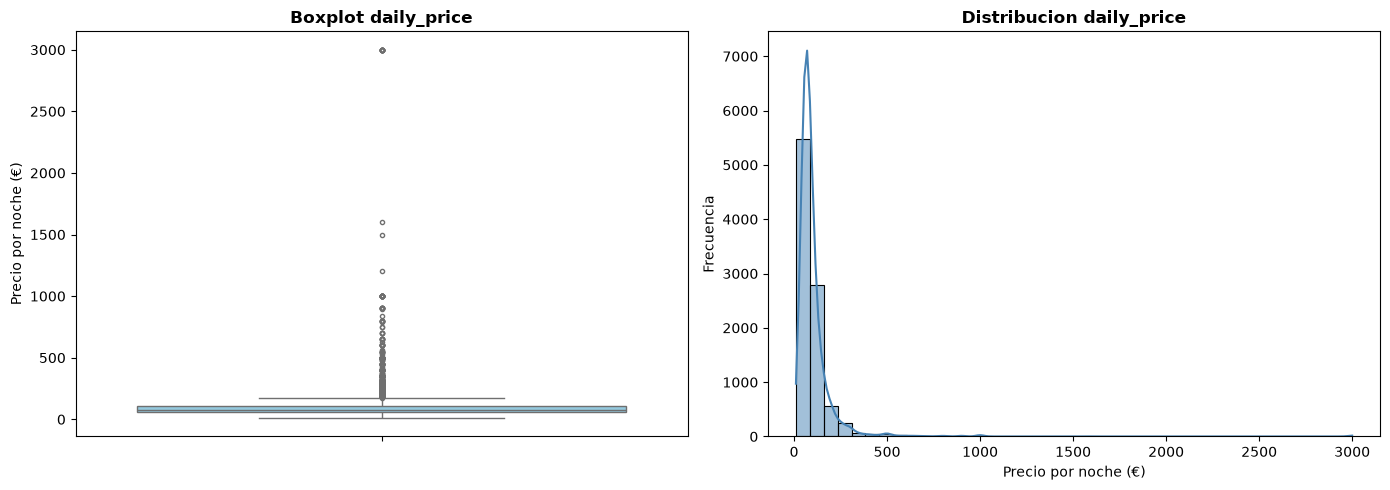

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
sns.boxplot(y=df_analisis['daily_price'], ax=axes[0], color='skyblue', fliersize=3)
axes[0].set_title('Boxplot daily_price', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Precio por noche (€)')

# Histograma
sns.histplot(df_analisis['daily_price'], kde=True, ax=axes[1], color='steelblue', bins=40)
axes[1].set_title('Distribucion daily_price', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Precio por noche (€)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

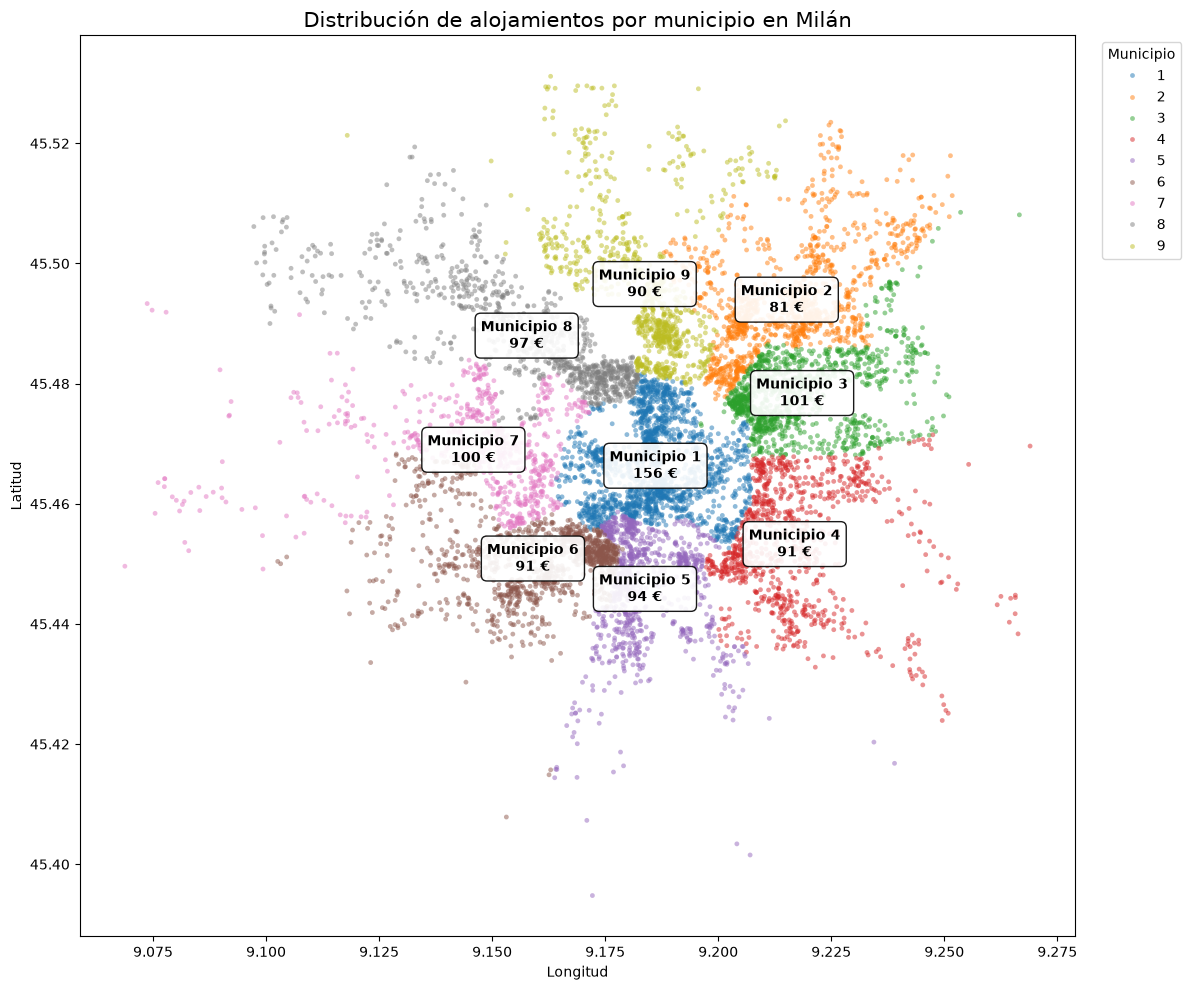

In [71]:
data = df_analisis[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].copy()

# Convertimos municipios a categorías
data["municipio"] = data["neighbourhood_cleansed"].astype(str)

# Estadísticas por municipio
municipios = (
    data.groupby("municipio")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        precio_medio=("daily_price", "mean"),
    )
    .reset_index()
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 10))

sns.scatterplot(
    data=data,
    x="longitude",
    y="latitude",
    hue="municipio",
    palette="tab10",
    s=12,
    alpha=0.5,
    linewidth=0,
    ax=ax,
)

# Etiquetas con municipio y precio mediano
for _, row in municipios.iterrows():
    ax.annotate(
        f"Municipio {row['municipio']}\n"
        f"{row['precio_medio']:.0f} €",
        xy=(row["longitude"], row["latitude"]),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="black",
            alpha=0.9,
        ),
    )

ax.set_title(
    "Distribución de alojamientos por municipio en Milán",
    fontsize=15,
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.legend(
    title="Municipio",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


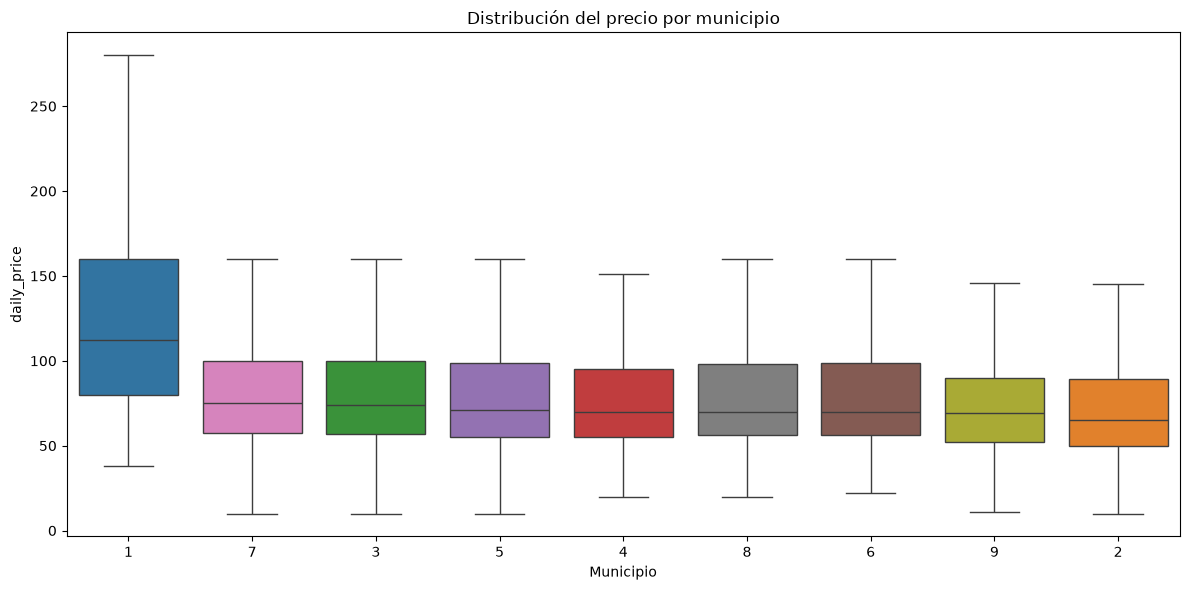

In [72]:
# Preparación
data = df_analisis[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# Ordenar municipios según el precio mediano
orden = (
    data.groupby("neighbourhood_cleansed")["daily_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x="neighbourhood_cleansed",
    y="daily_price",
    order=orden,
    hue="neighbourhood_cleansed",
    palette="tab10",
    showfliers=False,
    legend=False,
)

plt.title("Distribución del precio por municipio")
plt.xlabel("Municipio")
plt.ylabel("daily_price")
plt.tight_layout()
plt.show()

De estos gráficos vemos como la mayor diferencia de precios se da entre el Municipio 1 (céntrico) y los demás

Observemos la distribución de los precios por barrio

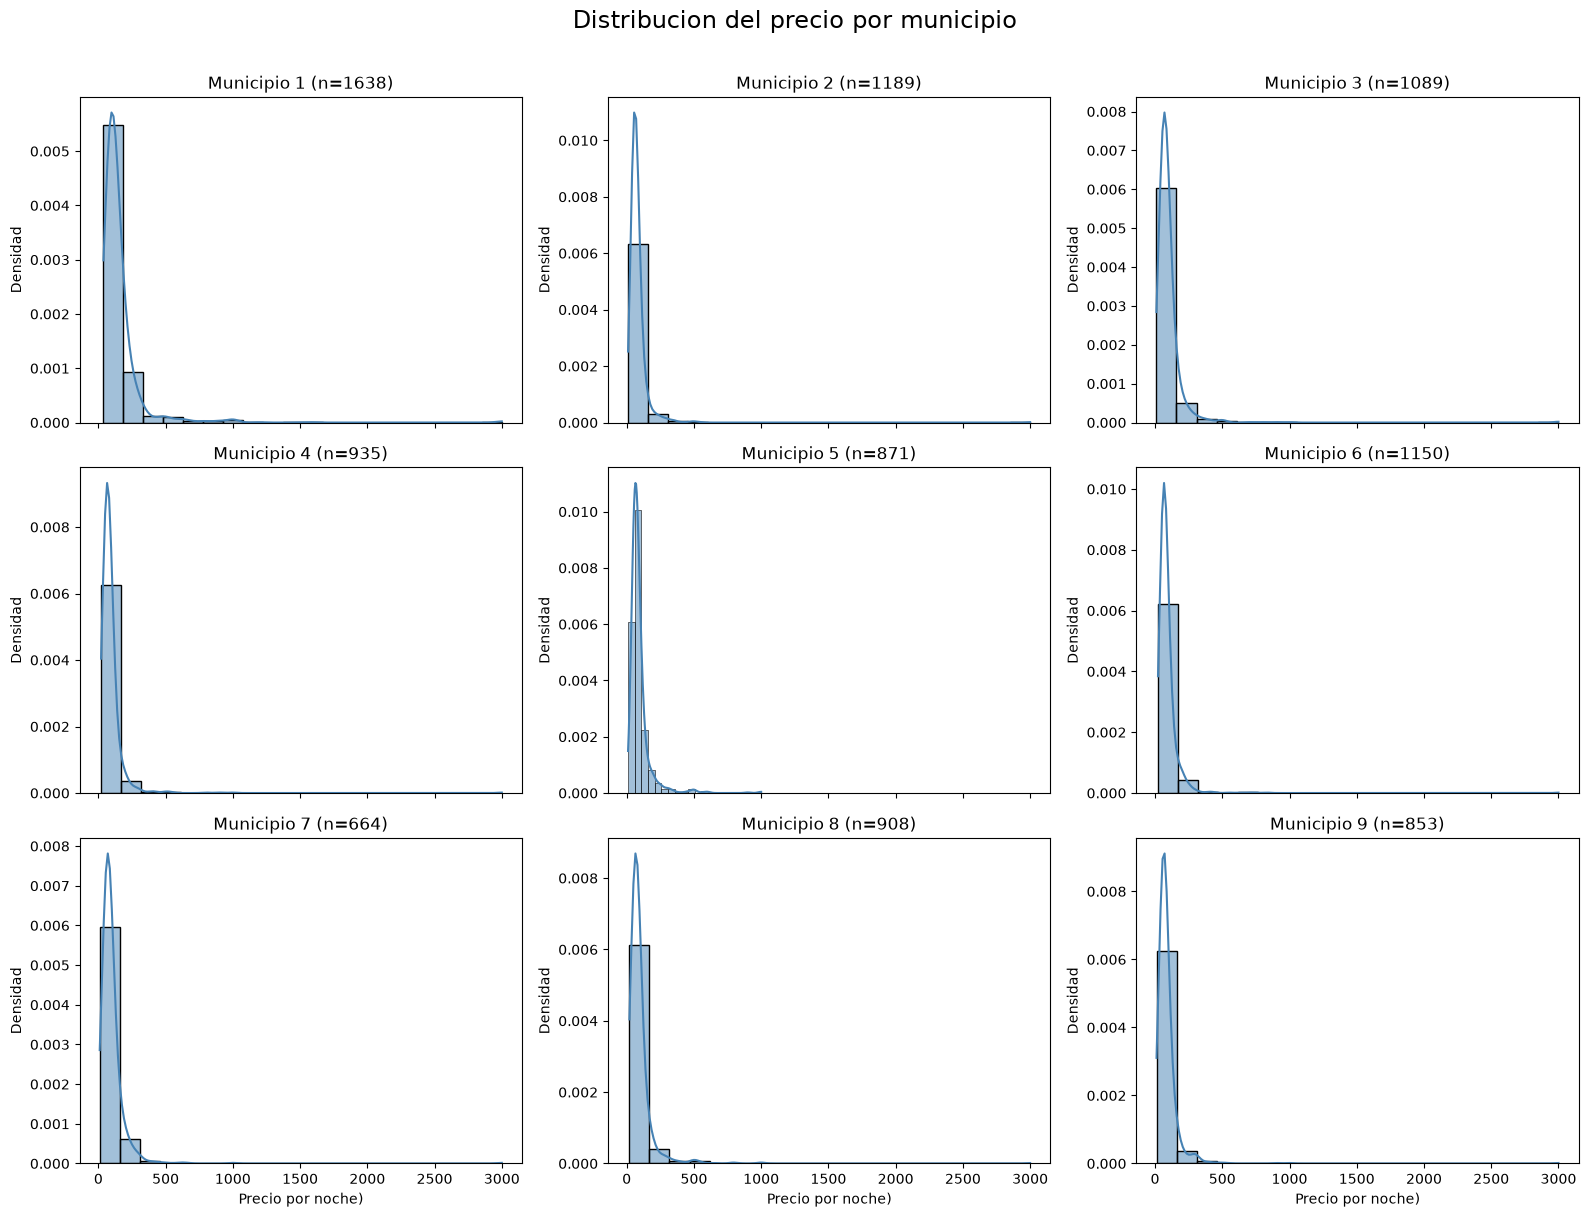

In [73]:
# Municipios ordenados
municipios = sorted(df_analisis["neighbourhood_cleansed"].unique())

def plot_histogramas_por_municipio(columna):
    n_cols = 3
    n_rows = ceil(len(municipios) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows),
        sharex=True
    )

    axes = np.array(axes).flatten()

    for ax, municipio in zip(axes, municipios):
        subset = df_analisis[
            df_analisis["neighbourhood_cleansed"] == municipio
        ]

        sns.histplot(
            data=subset,
            x=columna,
            bins=20,
            kde=True,
            stat="density",
            color="steelblue",
            ax=ax
        )

        ax.set_title(
            f"Municipio {municipio} (n={len(subset)})"
        )
        ax.set_xlabel("Precio por noche)")
        ax.set_ylabel("Densidad")

    fig.suptitle("Distribucion del precio por municipio", fontsize=17, y=1.01)
    plt.tight_layout()
    plt.show()

plot_histogramas_por_municipio("daily_price")

Hacemos una transformación logaritmica

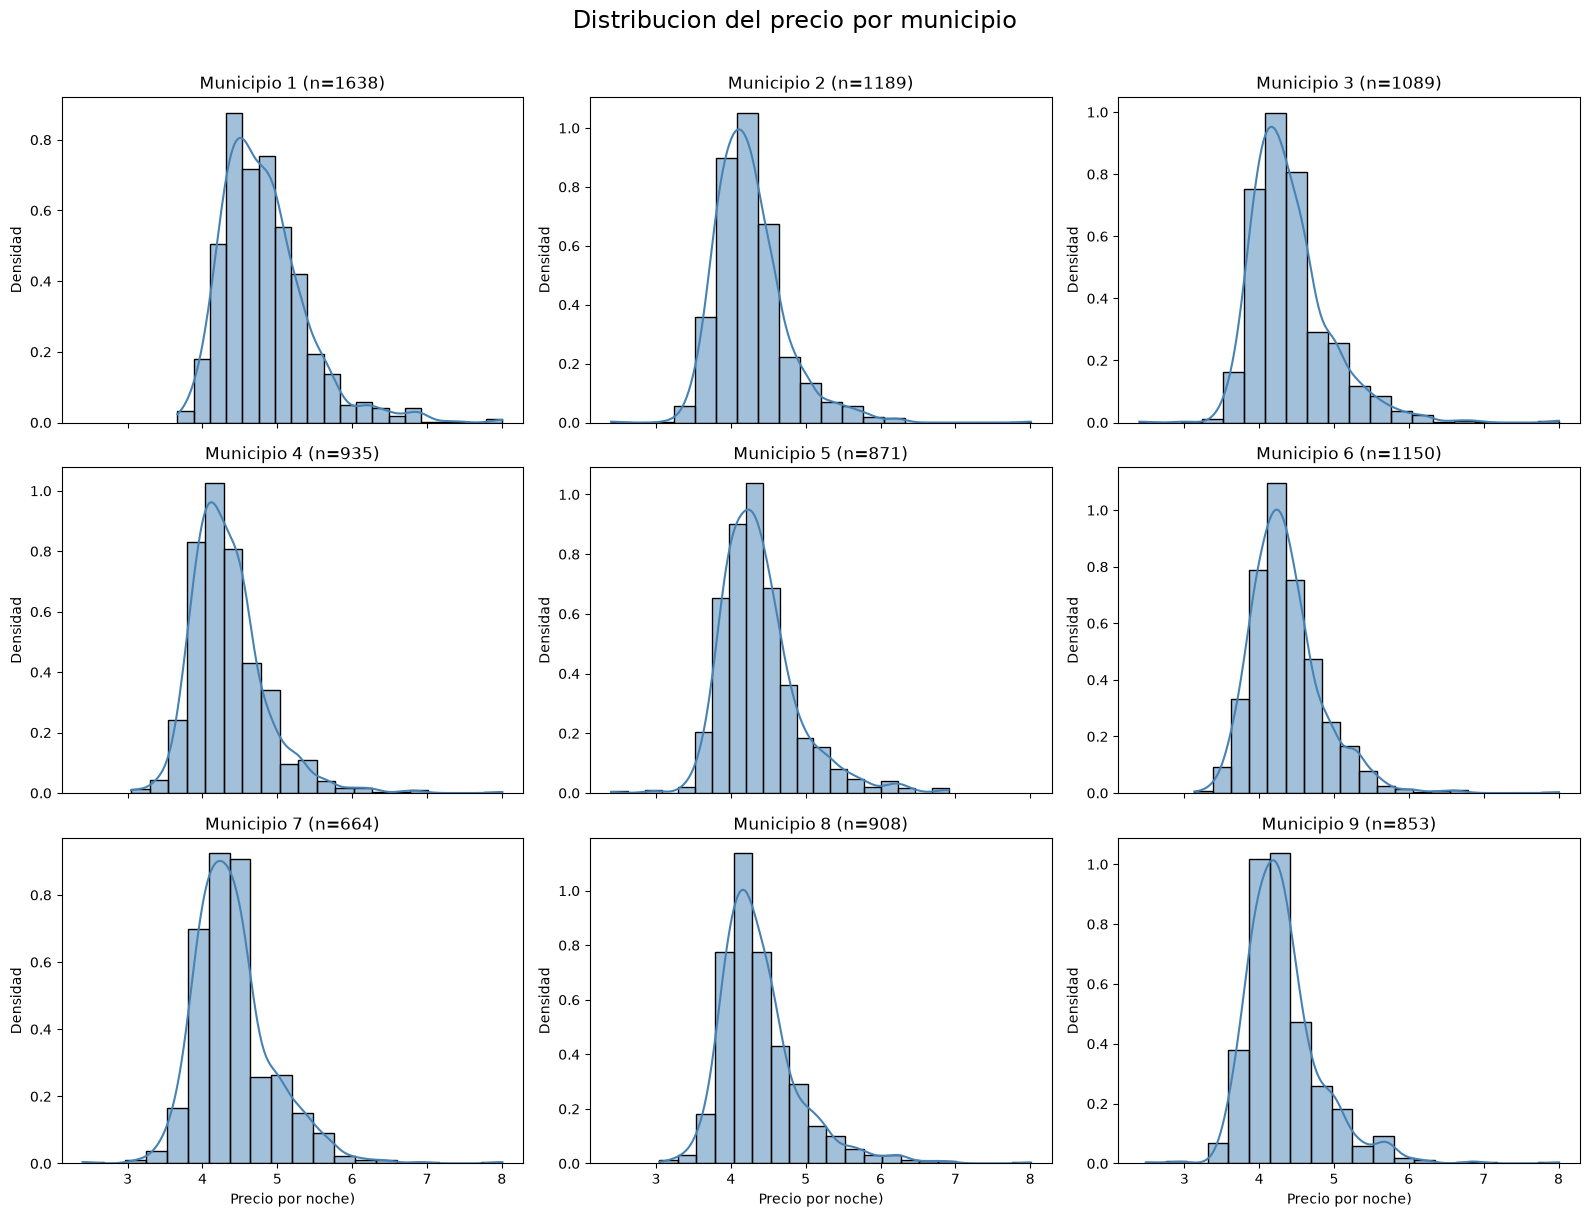

In [74]:
df_analisis["log_daily_price"] = np.log1p(df_analisis["daily_price"]) # log(1 + x) para que quede positivo

plot_histogramas_por_municipio("log_daily_price")

POR QUE HACEMOS ESTA TRANSFORMACION?
* La rgresion lineal asume que los errores se distribuyen de manera normal. Los precios de los alquileres tienen una asimetria positiva extrema a derecha. Al aplicar el logaritmo, la distribucion se vuelve lognormal / simetrica, permitiendo que los residuos cumplan con la normalidad.
* En la escala original en euros, a medida que el departamento es máa grande o lujoso, el error de prediccion tiende a ser mucho mas grande. El logaritmo comprime las escalas altas y estabiliza la varianza de los errores a lo largo de todo el rango de precios.
* Si quisiesemos usar daily_price original en un modelo lineal estricto, nos veriamos obligados a eliminar outliers de la cola superior para que no arruinen la recta. Usar el logaritmo nos permite conservar el 100% de la muestra sin perder las propiedades de lujo legitimas.

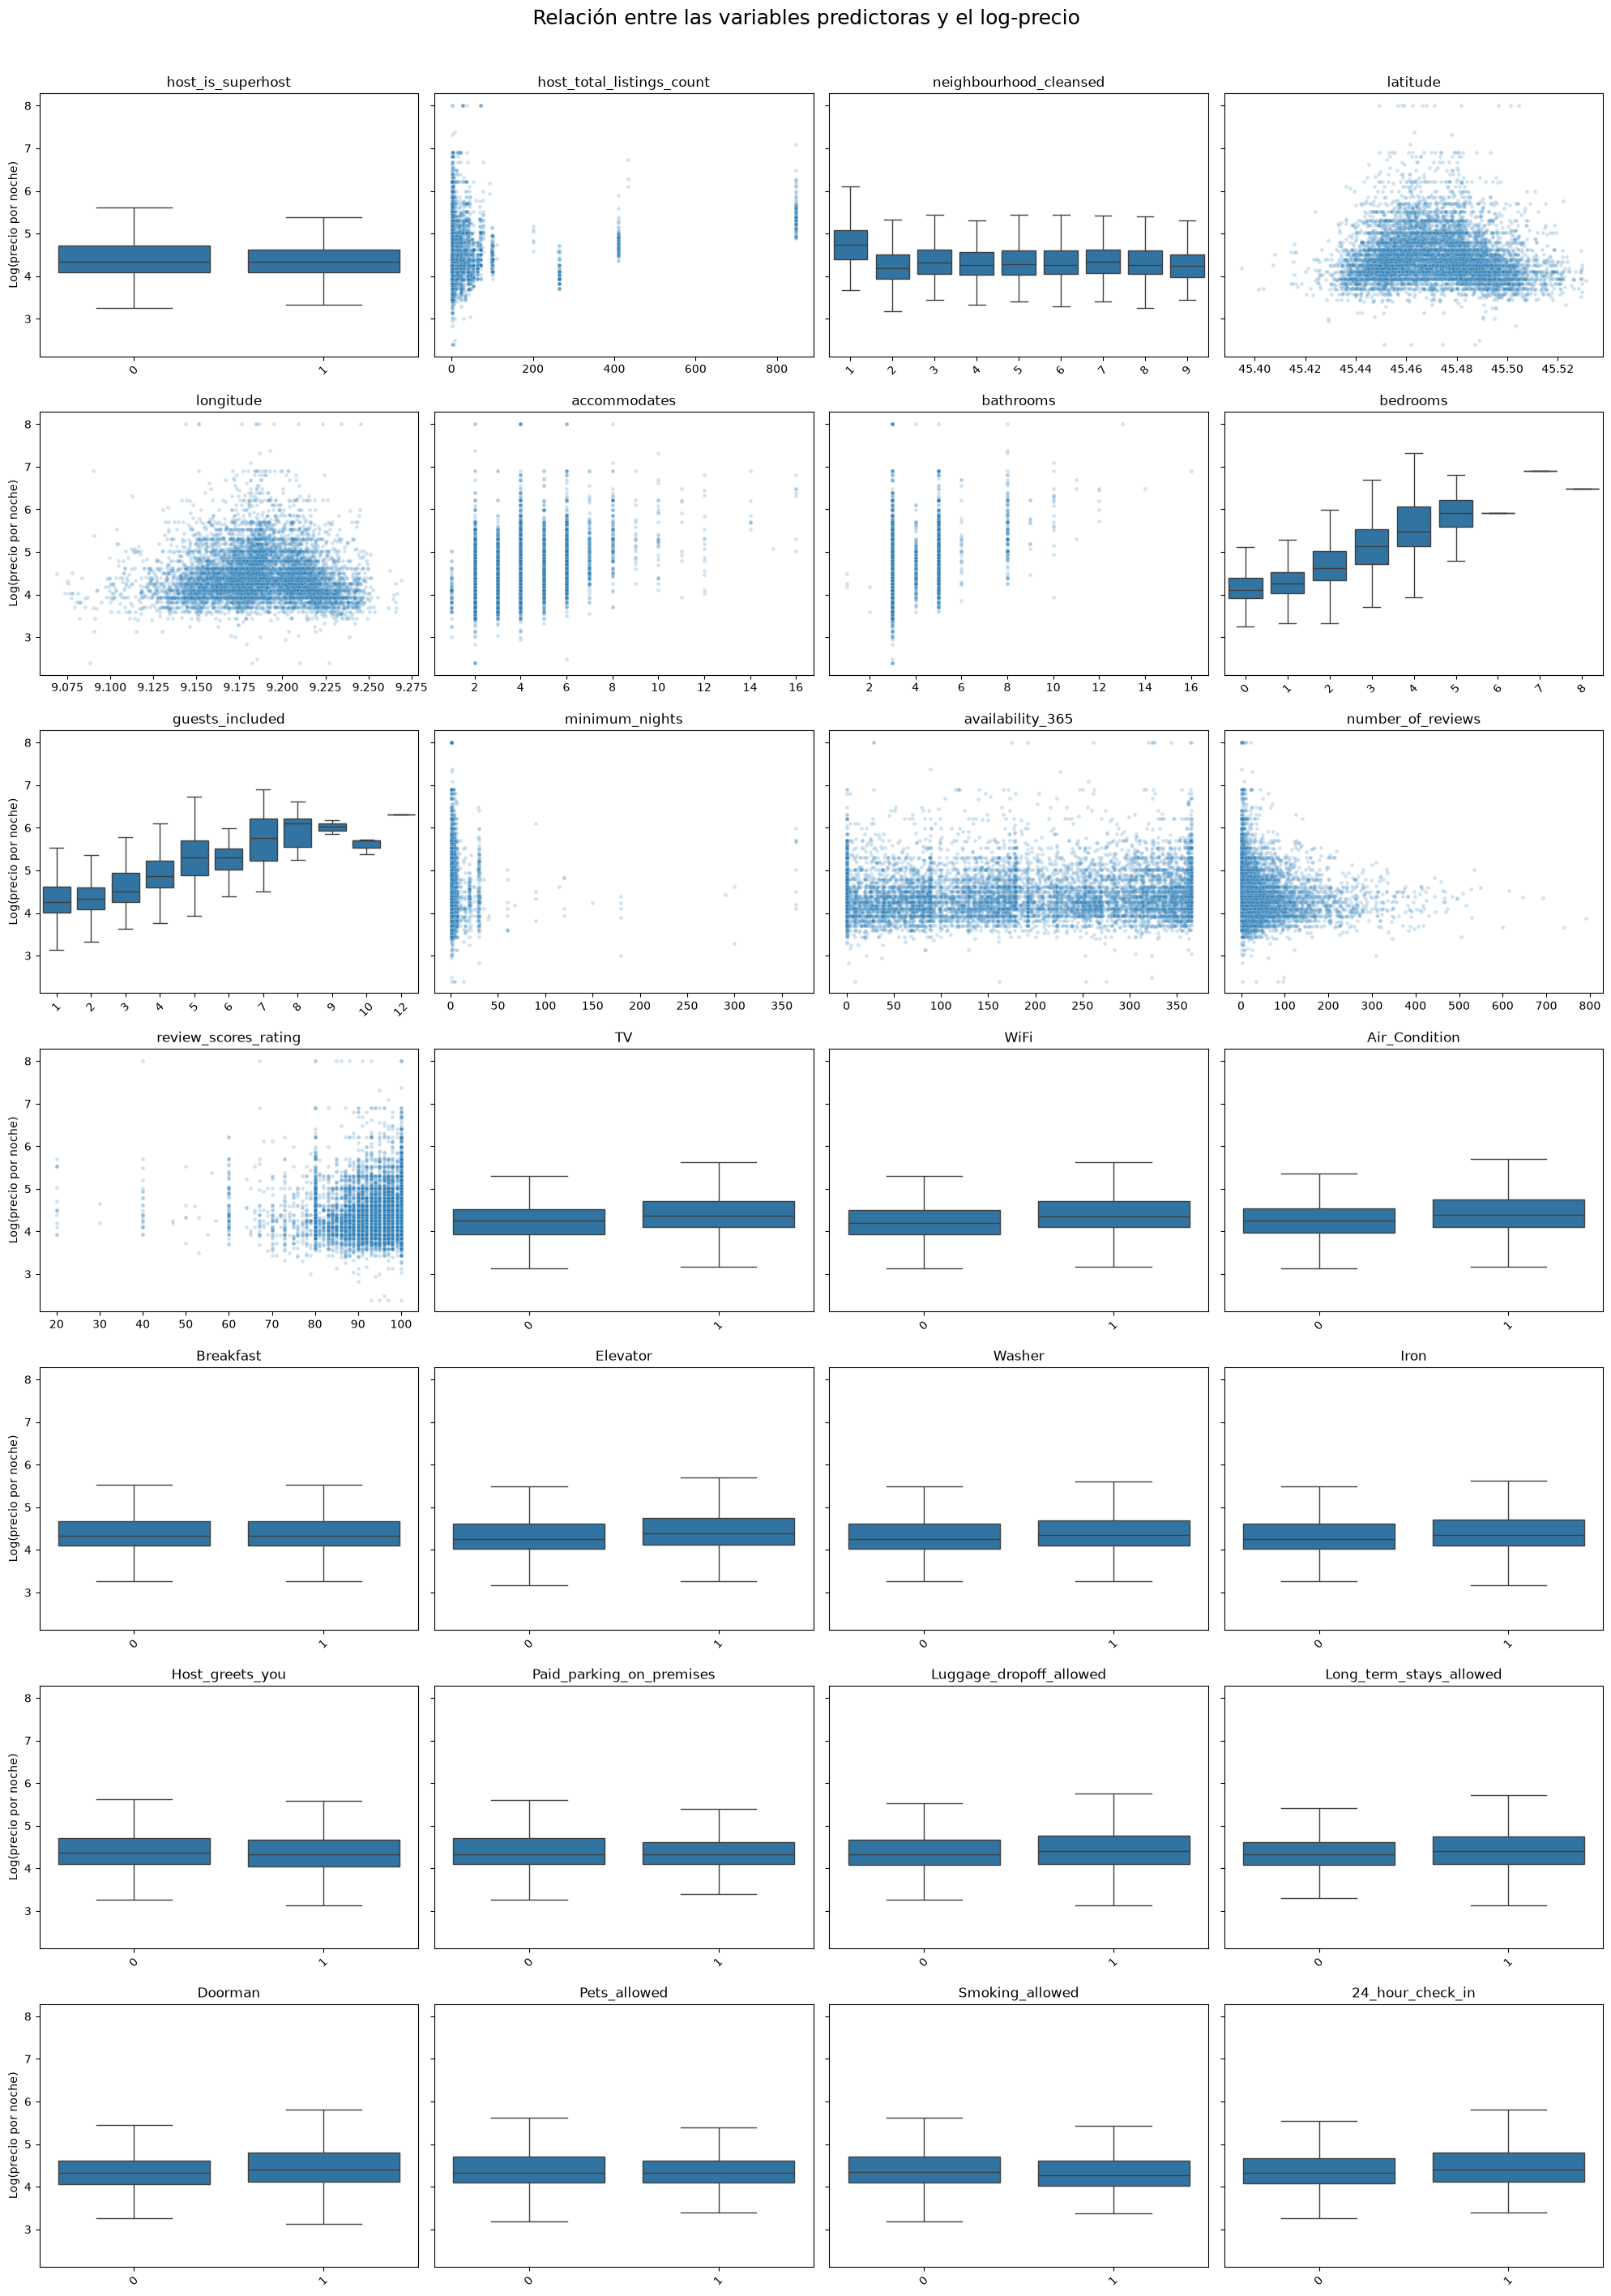

In [75]:
target = "log_daily_price"

# Excluir los targets
features = df_analisis.columns.drop(["daily_price", target])

# Configuración de la grilla
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 4 * n_rows),
    sharey=True
)

axes = axes.flatten()

for ax, col in zip(axes, features):

    # Variables categóricas o discretas con pocos valores
    es_categorica = (
        not pd.api.types.is_numeric_dtype(df_analisis[col])
        or col == "neighbourhood_cleansed"
        or df_analisis[col].nunique() <= 12
    )

    if es_categorica:
        sns.boxplot(
            data=df_analisis,
            x=col,
            y=target,
            showfliers=False,
            ax=ax
        )
        ax.tick_params(axis="x", rotation=45)

    else:
        sns.scatterplot(
            data=df_analisis,
            x=col,
            y=target,
            alpha=0.2,
            s=12,
            ax=ax
        )

    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Log(precio por noche)")

# Eliminar ejes sobrantes
for ax in axes[len(features):]:
    ax.remove()

fig.suptitle(
    "Relación entre las variables predictoras y el log-precio",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

# ANALIZAR!

Transformaciones finales y guardado del dataset filtrado

In [77]:
# Antes de tomar la muestra cambiamos el nombre de la variable 24_hour_check_in
# porque al tener un número adelante no lo toma bien en la formula para el OLS.
df_eda = df_analisis.rename(columns={"24_hour_check_in": "check_in_24_hour"})

# Eliminamos el daily price ya que cambiamos la variable objetivo a su logaritmo
df_eda.drop(columns="daily_price", inplace=True)

# Guardamos el dataset filtrado y transformado
df_eda.to_csv(PROJECT_DIR / "datos/procesados/milan_airbnb_filtrado.csv", index=False)